In [2]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import os


/home/a/andriychenko/nobackups/envs/gencast/lib/python3.11/site-packages/xarray/core/indexes.py:641: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  flat_indexer = index.get_indexer(
/home/a/andriychenko/nobackups/envs/gencast/lib/python3.11/site-packages/xarray/core/indexes.py:641: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  flat_indexer = index.get_indexer(
/home/a/andriychenko/nobackups/envs/gencast/lib/python3.11/site-packages/xarray/core/indexes.py:641: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  flat_indexer = index.get_indexer(


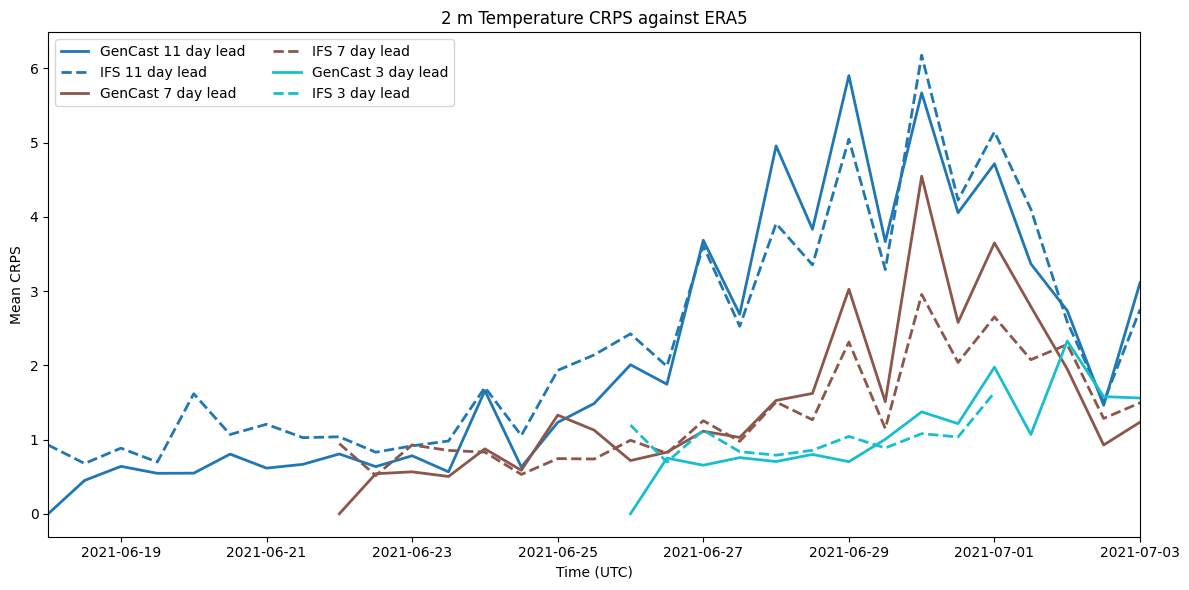

In [3]:
REGION = (45, 52, -123, -119)
ERA5_NC = "/home/a/andriychenko/Projects/graphcast/era5_pnw025_2021.nc"

runs = [
    {
        "label": "11 day lead",
        "gencast": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/init_2021-06-18T00_26d_50ens_26-0s_24-1s_predictions.zarr",
        "ifs": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/control/sfc/oper_pf_2021-06-18.nc",
        "start_time": "2021-06-18 00:00:00",
    },
    {
        "label": "7 day lead",
        "gencast": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/init_2021-06-22T00_18d_50ens_26-0s_24-1s_predictions.zarr",
        "ifs": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/control/sfc/oper_pf_2021-06-22.nc",
        "start_time": "2021-06-22 00:00:00",
    },
    {
        "label": "3 day lead",
        "gencast": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/predictions/init_2021-06-26T00_10d_50ens_26-0s_24-1s_predictions.zarr",
        "ifs": "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/control/sfc/oper_pf_2021-06-26.nc",
        "start_time": "2021-06-26 00:00:00",
    },
]

GENCAST_VAR = "2m_temperature"
IFS_VAR = "t2m"
ERA5_VAR = "t2m"

def standardize_latlon_names(ds):
    """
    Rename common latitude/longitude coordinate names to lat/lon.
    Adjust this if your files use other names.
    """
    rename = {}
    candidates = [
        ("latitude", "lat"),
        ("longitude", "lon"),
        ("Latitude", "lat"),
        ("Longitude", "lon"),
        ("LATITUDE", "lat"),
        ("LONGITUDE", "lon"),
    ]
    for old, new in candidates:
        if old in ds.coords or old in ds.dims:
            rename[old] = new
    if rename:
        ds = ds.rename(rename)
    return ds


def normalize_longitude(ds, lon_name="lon"):
    """
    Convert 0..360 longitudes to -180..180 so all datasets line up.
    If your data are already in -180..180, this is a no-op.
    """
    if lon_name not in ds.coords:
        return ds

    lon = ds[lon_name]
    if float(lon.max()) > 180:
        ds = ds.assign_coords({lon_name: ((lon + 180) % 360) - 180}).sortby(lon_name)
    return ds


def pick_ensemble_dim(da):
    """
    Find the ensemble/member dimension if it exists.
    If no ensemble dimension exists, we will treat the forecast as
    a single-member ensemble.
    """
    for cand in ["member", "ensemble", "number", "realization", "ens"]:
        if cand in da.dims:
            return cand
    return None


def crps_calculation(ensemble, truth):
    ens_members = np.sort(ensemble[np.isfinite(ensemble)])

    if len(ens_members) == 0:
        return np.nan

    if len(ens_members) == 1:
        return abs(ens_members[0] - truth)

    crps = 0.0

    # Pseudo code:
    # CRPS = ∫ (F(y)-H(y-x))² dy
    for k in range(len(ens_members) - 1):

        y_k = ens_members[k]
        y_k1 = ens_members[k + 1]
        dy = y_k1 - y_k

        F_k = (k + 1) / len(ens_members)

        if y_k1 <= truth:
            # interval entirely below observation
            crps += (F_k ** 2) * dy

        elif y_k >= truth:
            # interval entirely above observation
            crps += ((F_k - 1) ** 2) * dy

        else:
            # observation lies inside interval
            crps += (F_k ** 2) * (truth - y_k)
            crps += ((F_k - 1) ** 2) * (y_k1 - truth)

    return crps

def compute_crps(forecast_da, obs_da):
    # Find the ensemble dimension
    ens_dim = None
    for dim in ["sample", "member", "ensemble", "number", "realization"]:
        if dim in forecast_da.dims:
            ens_dim = dim
            break

    if ens_dim is None:
        # Deterministic forecast -> treat as 1-member ensemble
        forecast_da = forecast_da.expand_dims(member=[0])
        ens_dim = "member"

    # CRPS needs the full ensemble vector at each point,
    # so make the ensemble dimension a single chunk.
    if forecast_da.chunks is not None:
        forecast_da = forecast_da.chunk({ens_dim: -1})

    crps = xr.apply_ufunc(
        crps_calculation,
        forecast_da,
        obs_da,
        input_core_dims=[[ens_dim], []],
        output_core_dims=[[]],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[float],
    )

    return crps

def score_one_initialization(gencast_zarr, ifs_nc, era5_nc, start_time, region=None):
    gc = xr.open_zarr(gencast_zarr)
    ifs = xr.open_dataset(ifs_nc)
    era5 = xr.open_dataset(era5_nc)

    gc = standardize_latlon_names(gc)
    ifs = standardize_latlon_names(ifs)
    era5 = standardize_latlon_names(era5)

    gc = normalize_longitude(gc)
    ifs = normalize_longitude(ifs)
    era5 = normalize_longitude(era5)

    gc_t = gc[GENCAST_VAR]
    ifs_t = ifs[IFS_VAR]
    era5_t = era5[ERA5_VAR]

    # GenCast time is elapsed time, with 0 = forecast init
    gc_t = gc_t.sel(time=slice(np.timedelta64(0, "ns"), None))

    gc_valid_times = pd.Timestamp(start_time) + pd.to_timedelta(gc_t["time"].values)
    gc_t = gc_t.assign_coords(time=gc_valid_times).sortby("time")

    # Align IFS and ERA5 to the same valid times
    ifs_t = ifs_t.reindex(time=gc_valid_times, method="nearest", tolerance="1H").sortby("time")
    era5_t = era5_t.reindex(time=gc_valid_times, method="nearest", tolerance="1H").sortby("time")

    # Use GenCast grid as the reference grid
    if "lat" not in gc.coords or "lon" not in gc.coords:
        raise ValueError("Could not find lat/lon coordinates in the GenCast dataset after renaming.")

    target_lat = gc["lat"]
    target_lon = gc["lon"]

    ifs_on_gc = ifs_t.interp(lat=target_lat, lon=target_lon)
    era5_on_gc = era5_t.interp(lat=target_lat, lon=target_lon)

    # Optional region subset
    if region is not None:
        lat_min, lat_max, lon_min, lon_max = region
        gc_t = gc_t.sel(lat=slice(lat_min, lat_max), lon=slice(lon_min, lon_max))
        ifs_on_gc = ifs_on_gc.sel(lat=slice(lat_min, lat_max), lon=slice(lon_min, lon_max))
        era5_on_gc = era5_on_gc.sel(lat=slice(lat_min, lat_max), lon=slice(lon_min, lon_max))

    crps_gencast = compute_crps(gc_t, era5_on_gc)
    crps_ifs = compute_crps(ifs_on_gc, era5_on_gc)

    crps_gencast_mean = crps_gencast.mean(dim=[d for d in crps_gencast.dims if d != "time"], skipna=True).squeeze()
    crps_ifs_mean = crps_ifs.mean(dim=[d for d in crps_ifs.dims if d != "time"], skipna=True).squeeze()

    return crps_gencast_mean, crps_ifs_mean


# ============================================================
# Run all initialisations and plot
# ============================================================

results = []

for run in runs:
    crps_gc_mean, crps_ifs_mean = score_one_initialization(
        run["gencast"],
        run["ifs"],
        ERA5_NC,
        run["start_time"],
        region=REGION,
    )

    results.append(
        {
            "label": run["label"],
            "gc": crps_gc_mean,
            "ifs": crps_ifs_mean,
        }
    )

plt.figure(figsize=(12, 6))
colors = plt.cm.tab10(np.linspace(0, 1, len(results)))

for color, res in zip(colors, results):
    plt.plot(
        res["gc"]["time"].values,
        res["gc"].values.ravel(),
        color=color,
        linestyle="-",
        linewidth=2,
        label=f"GenCast {res['label']}",
    )
    plt.plot(
        res["ifs"]["time"].values,
        res["ifs"].values.ravel(),
        color=color,
        linestyle="--",
        linewidth=2,
        label=f"IFS {res['label']}",
    )

plt.xlabel("Time (UTC)")
plt.ylabel("Mean CRPS")
plt.xlim(pd.Timestamp("2021-06-18"), pd.Timestamp("2021-07-03"))
plt.title("2 m Temperature CRPS against ERA5")
plt.legend(ncol=2)
plt.tight_layout()
plt.show()

# 7) Optional: save the per-location CRPS fields
#crps_gencast.to_netcdf("crps_gencast.nc")
#crps_ifs.to_netcdf("crps_ifs.nc")

/home/a/andriychenko/nobackups/envs/gencast/lib/python3.11/site-packages/xarray/core/indexes.py:641: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  flat_indexer = index.get_indexer(


/home/a/andriychenko/nobackups/envs/gencast/lib/python3.11/site-packages/xarray/core/indexes.py:641: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  flat_indexer = index.get_indexer(
/home/a/andriychenko/nobackups/envs/gencast/lib/python3.11/site-packages/xarray/core/indexes.py:641: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  flat_indexer = index.get_indexer(


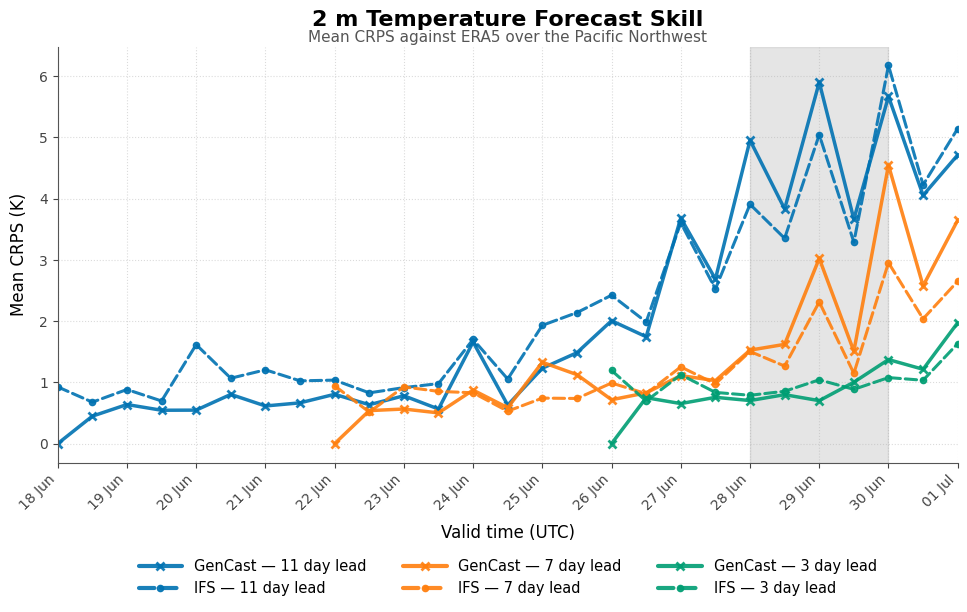

In [4]:
# ============================================================
# Run all initialisations and plot
# ============================================================

results = []

for run in runs:
    crps_gc_mean, crps_ifs_mean = score_one_initialization(
        run["gencast"],
        run["ifs"],
        ERA5_NC,
        run["start_time"],
        region=REGION,
    )

    results.append(
        {
            "label": run["label"],
            "gc": crps_gc_mean,
            "ifs": crps_ifs_mean,
        }
    )


# ============================================================
# Pretty CRPS plot
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd

fig, ax = plt.subplots(figsize=(10, 6.5))


# Shade 28–30 June 2021
ax.axvspan(
    pd.Timestamp("2021-06-28"),
    pd.Timestamp("2021-06-30"),
    color="grey",
    alpha=0.2,
    zorder=0,
)


# Colour palette: one colour per forecast lead
# Nice, colourblind-friendly-ish palette
colours = {
    "11 day lead": "#0072B2",  # blue
    "7 day lead": "#ff7f0e",   # orange
    "3 day lead": "#009E73",   # green
}


# Plot each lead time
for res in results:
    colour = colours[res["label"]]

    # GenCast — solid, small crosses
    ax.plot(
        res["gc"]["time"].values,
        res["gc"].values.ravel(),
        color=colour,
        linestyle="-",
        linewidth=2.5,
        alpha=0.9,
        marker="x",
        markersize=6,
        markeredgewidth=2,
        label=f"GenCast — {res['label']}",
        solid_capstyle="round",
    )

    # IFS — dashed, small dots
    ax.plot(
        res["ifs"]["time"].values,
        res["ifs"].values.ravel(),
        color=colour,
        linestyle="--",
        alpha=0.9,
        linewidth=2.2,
        marker="o",
        markersize=4.5,
        label=f"IFS — {res['label']}",
        dash_capstyle="round",
    )


# ------------------------------------------------------------
# Axes
# ------------------------------------------------------------

ax.set_xlabel(
    "Valid time (UTC)",
    fontsize=12,
    labelpad=8,
)

ax.set_ylabel(
    "Mean CRPS (K)",
    fontsize=12,
    labelpad=8,
)

ax.set_xlim(
    pd.Timestamp("2021-06-18"),
    pd.Timestamp("2021-07-01"),
)


# Date formatting
ax.xaxis.set_major_locator(
    mdates.DayLocator(interval=1)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b")
)

plt.setp(
    ax.get_xticklabels(),
    rotation=45,
    ha="right",
)


# ------------------------------------------------------------
# Title
# ------------------------------------------------------------

ax.set_title(
    "2 m Temperature Forecast Skill",
    fontsize=16,
    fontweight="bold",
    pad=15,
)

ax.text(
    0.5,
    1.005,
    "Mean CRPS against ERA5 over the Pacific Northwest",
    transform=ax.transAxes,
    ha="center",
    va="bottom",
    fontsize=11,
    color="#555555",
)


# ------------------------------------------------------------
# Grid and spines
# ------------------------------------------------------------

ax.grid(
    True,
    which="major",
    axis="both",
    linestyle=":",
    linewidth=0.8,
    color="#B0B0B0",
    alpha=0.45,
)

# Keep only left and bottom spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#555555")
ax.spines["bottom"].set_color("#555555")

ax.tick_params(
    axis="both",
    which="major",
    labelsize=10,
    colors="#444444",
)


# ------------------------------------------------------------
# Legend — two columns
# ------------------------------------------------------------

legend = ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.20),
    ncol=3,
    frameon=False,
    fontsize=10.5,
    handlelength=3,
    columnspacing=2.5,
    handletextpad=0.8,
)

# Make legend lines slightly thicker
for line in legend.get_lines():
    line.set_linewidth(3)


# ------------------------------------------------------------
# Layout
# ------------------------------------------------------------

fig.subplots_adjust(
    left=0.08,
    right=0.98,
    top=0.88,
    bottom=0.24,
)

plt.show()

In [4]:
# ============================================================
# PATHS
# ============================================================

GENCAST_DIR = (
    "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/"
    "predictions"
)

IFS_DIR = (
    "/network/group/aopp/predict/MK004_ANDRIYCHENKO_GENCAST/"
    "control/pl"
)

# ERA5 file covering the full verification period
ERA5_NC = (
    "/home/a/andriychenko/Projects/graphcast/"
    "init_files/init_2021-06-17T12_30d.nc"
)


# ============================================================
# Region
# ============================================================

REGION = {
    "north": 70,
    "west": -150,
    "south": 30,
    "east": -100,
}


# ============================================================
# Initialisations
# ============================================================

initialisations = [
    {
        "label": "11 day lead",
        "date": "2021-06-18",
    },
    {
        "label": "7 day lead",
        "date": "2021-06-18",
    },
    {
        "label": "3 day lead",
        "date": "2021-06-18",
    },
]


# ============================================================
# Find relevant files automatically
# ============================================================

runs = []

for info in initialisations:

    date = info["date"]

    # --------------------------------------------------------
    # GenCast
    #
    # Looks specifically for the UNPERTURBED forecast:
    # init_YYYY-MM-DDT00_..._predictions.zarr
    # --------------------------------------------------------

    gc_pattern = os.path.join(
        GENCAST_DIR,
        f"init_{date}T00_*_predictions.zarr"
    )

    gc_matches = sorted(glob.glob(gc_pattern))

    if len(gc_matches) == 0:
        raise FileNotFoundError(
            f"No GenCast file found for {date}\n"
            f"Pattern used:\n{gc_pattern}"
        )

    if len(gc_matches) > 1:
        print(f"WARNING: multiple GenCast files for {date}:")
        for x in gc_matches:
            print("   ", x)
        print("Using:", gc_matches[0])

    gencast_file = gc_matches[0]


    # --------------------------------------------------------
    # IFS
    # --------------------------------------------------------

    ifs_file = os.path.join(
        IFS_DIR,
        f"oper_pf_pl_{date}.nc"
    )

    if not os.path.exists(ifs_file):
        raise FileNotFoundError(
            f"IFS file not found:\n{ifs_file}"
        )


    runs.append(
        {
            "label": info["label"],
            "date": date,
            "start_time": np.datetime64(date + "T00:00:00"),
            "gencast": gencast_file,
            "ifs": ifs_file,
        }
    )


print("Files found:")
print()

for run in runs:
    print(run["label"])
    print("  GenCast:", run["gencast"])
    print("  IFS:    ", run["ifs"])
    print()

print("ERA5:")
print(" ", ERA5_NC)


# ============================================================
# Variable configuration
# ============================================================

variables = {
    "z500": {
        "gc_var": "geopotential",
        "ifs_var": "z",
        "era5_var": "geopotential",
        "level": 500,
        "title": "500 hPa Geopotential Forecast Skill",
        "ylabel": "Mean CRPS (m² s⁻²)",
    },

    "q1000": {
        "gc_var": "specific_humidity",
        "ifs_var": "q",
        "era5_var": "specific_humidity",
        "level": 1000,
        "title": "1000 hPa Specific Humidity Forecast Skill",
        "ylabel": "Mean CRPS (kg kg⁻¹)",
    },
}


# ============================================================
# Helpers
# ============================================================

def open_any(path):
    if path.endswith(".zarr"):
        return xr.open_zarr(path)
    return xr.open_dataset(path)


def standardize_coords(da):
    """
    Standardize lat/lon and ensemble dimension names.
    """

    rename = {}

    # Spatial coordinates
    if "latitude" in da.dims:
        rename["latitude"] = "lat"
    elif "latitude" in da.coords:
        rename["latitude"] = "lat"

    if "longitude" in da.dims:
        rename["longitude"] = "lon"
    elif "longitude" in da.coords:
        rename["longitude"] = "lon"

    # Ensemble coordinate
    for ens_name in [
        "sample",
        "number",
        "member",
        "ensemble",
        "realization",
    ]:
        if ens_name in da.dims and ens_name != "member":
            rename[ens_name] = "member"
            break

    if rename:
        da = da.rename(rename)

    # Remove singleton dimensions that are not useful
    for dim in list(da.dims):
        if (
            da.sizes[dim] == 1
            and dim not in ["time", "member", "lat", "lon"]
        ):
            da = da.squeeze(dim, drop=True)

    # Standard latitude ordering
    if "lat" in da.coords:
        da = da.sortby("lat")

    return da


def get_level_name(da):
    """
    Find pressure-level coordinate name.
    """

    candidates = [
        "level",
        "pressure_level",
        "isobaricInhPa",
        "plev",
    ]

    for name in candidates:
        if name in da.coords or name in da.dims:
            return name

    return None


def select_level(da, level):
    """
    Select pressure level, handling hPa or Pa coordinates.
    """

    level_name = get_level_name(da)

    if level_name is None:
        raise ValueError(
            f"No pressure-level coordinate found.\n"
            f"Dimensions: {da.dims}\n"
            f"Coordinates: {list(da.coords)}"
        )

    levels = da[level_name]

    # Determine whether coordinate is hPa or Pa
    if float(levels.max()) > 2000:
        target = level * 100.0
    else:
        target = float(level)

    da = da.sel(
        {level_name: target},
        method="nearest"
    )

    return da


def make_valid_time(da, start_time):
    """
    Make sure forecast data use valid datetime coordinates.

    Handles:
      - datetime time
      - timedelta time
      - numerical forecast hours
      - separate step dimension
    """

    # --------------------------------------------------------
    # valid_time already exists as 1-D dimension
    # --------------------------------------------------------

    if "valid_time" in da.coords:

        vt = da["valid_time"]

        if vt.ndim == 1:

            dim = vt.dims[0]

            if dim != "time":
                da = da.assign_coords(
                    time=(dim, vt.values)
                )
                da = da.swap_dims({dim: "time"})

            return da


    # --------------------------------------------------------
    # Separate forecast step dimension
    # --------------------------------------------------------

    if "step" in da.dims:

        step = da["step"]

        # Convert forecast step to timedelta
        if np.issubdtype(step.dtype, np.timedelta64):
            valid = start_time + step.values

        else:
            valid = (
                start_time
                + step.values.astype(float)
                * np.timedelta64(1, "h")
            )

        # If there is a singleton initialization-time dimension,
        # remove it first.
        if "time" in da.dims and da.sizes["time"] == 1:
            da = da.isel(time=0, drop=True)

        da = da.assign_coords(
            valid_time=("step", valid)
        )

        da = da.swap_dims(
            {"step": "valid_time"}
        )

        da = da.rename(
            {"valid_time": "time"}
        )

        return da


    # --------------------------------------------------------
    # Normal time coordinate
    # --------------------------------------------------------

    if "time" in da.coords:

        t = da["time"]

        if np.issubdtype(t.dtype, np.datetime64):
            return da

        if np.issubdtype(t.dtype, np.timedelta64):

            return da.assign_coords(
                time=start_time + t
            )

        if np.issubdtype(t.dtype, np.number):

            return da.assign_coords(
                time=(
                    start_time
                    + t.values.astype(float)
                    * np.timedelta64(1, "h")
                )
            )

    return da


def subset_region(da, region):
    """
    Subset to PNW region.

    Converts negative longitude bounds to 0–360 where necessary.
    """

    da = da.sortby("lat")

    north = region["north"]
    south = region["south"]
    west = region["west"]
    east = region["east"]

    # Latitude
    da = da.sel(
        lat=slice(south, north)
    )

    # Longitude
    lonmax = float(da.lon.max())

    if lonmax > 180:
        west = west % 360
        east = east % 360

    # Region here does not cross 0°
    da = da.sel(
        lon=slice(west, east)
    )

    return da


def prepare_field(
    path,
    variable,
    level,
    start_time,
    region,
):
    """
    Open one variable, select pressure level,
    convert time, and subset region.
    """

    ds = open_any(path)

    if variable not in ds.data_vars:
        raise KeyError(
            f"\nVariable '{variable}' not found in:\n"
            f"{path}\n\n"
            f"Available variables:\n"
            f"{list(ds.data_vars)}"
        )

    da = ds[variable]

    da = standardize_coords(da)

    if level is not None:
        da = select_level(
            da,
            level
        )

    da = make_valid_time(
        da,
        start_time
    )

    da = subset_region(
        da,
        region
    )

    return da


def interpolate_obs_to_forecast(obs, fc):
    """
    Interpolate ERA5 onto the forecast model grid.

    This is important because GenCast and IFS do not necessarily
    use exactly the same spatial grid.
    """

    obs = obs.sortby("lat")
    fc = fc.sortby("lat")

    obs_interp = obs.interp(
        lat=fc.lat,
        lon=fc.lon
    )

    return obs_interp

def crps_ensemble(fc, obs):
    """
    Ensemble CRPS.

    CRPS = mean |x_i - y|
           - 1/2 mean |x_i - x_j|
    """

    if "member" not in fc.dims:
        raise ValueError(
            f"No ensemble dimension found.\n"
            f"Forecast dimensions: {fc.dims}"
        )

    # IMPORTANT:
    # put the full ensemble dimension into a single Dask chunk
    if hasattr(fc.data, "chunks"):
        fc = fc.chunk({"member": -1})

    n = fc.sizes["member"]

    # First term
    term1 = np.abs(
        fc - obs
    ).mean(
        "member",
        skipna=True
    )

    # Sort ensemble members
    fc_sorted = xr.apply_ufunc(
        np.sort,
        fc,
        input_core_dims=[["member"]],
        output_core_dims=[["member"]],
        vectorize=False,
        dask="parallelized",
        output_dtypes=[fc.dtype],
    )

    coeff = xr.DataArray(
        2 * np.arange(1, n + 1) - n - 1,
        dims=["member"],
        coords={"member": fc_sorted["member"]},
    )

    term2 = (
        (fc_sorted * coeff)
        .sum("member", skipna=True)
        / (n ** 2)
    )

    return term1 - term2

def area_weighted_mean(da):
    """
    Cos(latitude)-weighted regional mean.
    """

    weights = np.cos(
        np.deg2rad(da.lat)
    )

    return da.weighted(
        weights
    ).mean(
        dim=("lat", "lon"),
        skipna=True
    )


# ============================================================
# Load ERA5 once
# ============================================================

era5_ds = open_any(ERA5_NC)


# ============================================================
# Score one initialization
# ============================================================

def score_one_initialization(
    run,
    cfg,
):

    # --------------------------------------------------------
    # GenCast
    # --------------------------------------------------------

    gc = prepare_field(
        run["gencast"],
        cfg["gc_var"],
        cfg["level"],
        run["start_time"],
        REGION,
    )


    # --------------------------------------------------------
    # IFS
    # --------------------------------------------------------

    ifs = prepare_field(
        run["ifs"],
        cfg["ifs_var"],
        cfg["level"],
        run["start_time"],
        REGION,
    )


    # --------------------------------------------------------
    # ERA5
    # --------------------------------------------------------

    if cfg["era5_var"] not in era5_ds:
        raise KeyError(
            f"ERA5 variable '{cfg['era5_var']}' not found.\n"
            f"Available variables:\n"
            f"{list(era5_ds.data_vars)}"
        )

    era5 = era5_ds[
        cfg["era5_var"]
    ]

    era5 = standardize_coords(
        era5
    )

    era5 = select_level(
        era5,
        cfg["level"]
    )

    era5 = make_valid_time(
        era5,
        np.datetime64("2021-06-17T12:00:00")
    )

    era5 = subset_region(
        era5,
        REGION
    )


    # ========================================================
    # GenCast vs ERA5
    # ========================================================

    era5_gc = interpolate_obs_to_forecast(
        era5,
        gc
    )

    gc, era5_gc = xr.align(
        gc,
        era5_gc,
        join="inner"
    )

    crps_gc = crps_ensemble(
        gc,
        era5_gc
    )

    crps_gc_mean = area_weighted_mean(
        crps_gc
    )


    # ========================================================
    # IFS vs ERA5
    # ========================================================

    era5_ifs = interpolate_obs_to_forecast(
        era5,
        ifs
    )

    ifs, era5_ifs = xr.align(
        ifs,
        era5_ifs,
        join="inner"
    )

    crps_ifs = crps_ensemble(
        ifs,
        era5_ifs
    )

    crps_ifs_mean = area_weighted_mean(
        crps_ifs
    )


    return (
        crps_gc_mean,
        crps_ifs_mean,
    )


# ============================================================
# Run all initialisations / variables
# ============================================================

all_results = {}

for key, cfg in variables.items():

    print()
    print("=" * 60)
    print(cfg["title"])
    print("=" * 60)

    results = []

    for run in runs:

        print(
            f"Scoring {run['label']} "
            f"({run['date']})..."
        )

        gc_crps, ifs_crps = (
            score_one_initialization(
                run,
                cfg,
            )
        )

        results.append(
            {
                "label": run["label"],
                "gc": gc_crps,
                "ifs": ifs_crps,
            }
        )

    all_results[key] = results


# ============================================================
# Plot
# ============================================================

fig, axes = plt.subplots(
    2,
    1,
    figsize=(13, 11),
    sharex=True,
)


colours = {
    "11 day lead": "#0072B2",
    "7 day lead":  "#ff7f0e",
    "3 day lead":  "#009E73",
}


plot_order = [
    "z500",
    "q1000",
]


for ax, key in zip(
    axes,
    plot_order
):

    cfg = variables[key]
    results = all_results[key]


    # --------------------------------------------------------
    # Heatwave period
    # --------------------------------------------------------

    ax.axvspan(
        pd.Timestamp("2021-06-28"),
        pd.Timestamp("2021-06-30"),
        color="grey",
        alpha=0.2,
        zorder=0,
    )


    # --------------------------------------------------------
    # Forecasts
    # --------------------------------------------------------

    for res in results:

        colour = colours[
            res["label"]
        ]


        # GenCast
        ax.plot(
            res["gc"].time.values,
            res["gc"].values.ravel(),
            color=colour,
            linestyle="-",
            linewidth=2.5,
            alpha=0.9,
            marker="x",
            markersize=6,
            markeredgewidth=2,
            label=(
                f"GenCast — "
                f"{res['label']}"
            ),
        )


        # IFS
        ax.plot(
            res["ifs"].time.values,
            res["ifs"].values.ravel(),
            color=colour,
            linestyle="--",
            linewidth=2.2,
            alpha=0.9,
            marker="o",
            markersize=4.5,
            label=(
                f"IFS — "
                f"{res['label']}"
            ),
        )


    # --------------------------------------------------------
    # Labels
    # --------------------------------------------------------

    ax.set_ylabel(
        cfg["ylabel"],
        fontsize=12,
        labelpad=8,
    )

    ax.set_title(
        cfg["title"],
        fontsize=16,
        fontweight="bold",
        pad=15,
    )

    ax.text(
        0.5,
        1.005,
        "Mean CRPS against ERA5 over the Pacific Northwest",
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=11,
        color="#555555",
    )


    # --------------------------------------------------------
    # Appearance
    # --------------------------------------------------------

    ax.grid(
        True,
        which="major",
        axis="both",
        linestyle=":",
        linewidth=0.8,
        color="#B0B0B0",
        alpha=0.45,
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.spines["left"].set_color(
        "#555555"
    )

    ax.spines["bottom"].set_color(
        "#555555"
    )

    ax.tick_params(
        axis="both",
        labelsize=10,
        colors="#444444",
    )

    ax.set_xlim(
        pd.Timestamp("2021-06-18"),
        pd.Timestamp("2021-07-03"),
    )


# ============================================================
# Date formatting
# ============================================================

axes[-1].set_xlabel(
    "Valid time (UTC)",
    fontsize=12,
    labelpad=8,
)

axes[-1].xaxis.set_major_locator(
    mdates.DayLocator(interval=1)
)

axes[-1].xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b")
)

plt.setp(
    axes[-1].get_xticklabels(),
    rotation=45,
    ha="right",
)


# ============================================================
# Shared legend
# ============================================================

handles, labels = (
    axes[0].get_legend_handles_labels()
)

legend = fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.015),
    ncol=3,
    frameon=False,
    fontsize=10.5,
    handlelength=3,
    columnspacing=2.5,
    handletextpad=0.8,
)

for line in legend.get_lines():
    line.set_linewidth(3)


# ============================================================
# Layout
# ============================================================

fig.subplots_adjust(
    left=0.10,
    right=0.98,
    top=0.95,
    bottom=0.12,
    hspace=0.35,
)

plt.show()

NameError: name 'glob' is not defined